# Chapitre 1 - Cours 1 : modèles de langage et tokens

Ce premier notebook accompagne la sous-section *From Language Models to Large Language
Models* du chapitre 1 (section *The Rise of AI Engineering*), et plus précisément son
premier volet, *Language models*. Le livre y pose le vocabulaire de base : qu'est-ce
qu'un modèle de langage, qu'est-ce qu'un **token**, pourquoi les modèles travaillent sur
des morceaux de mots, quelle différence entre un modèle **masqué** et un modèle
**autorégressif**, et pourquoi on peut voir un LLM comme une « completion machine ».

Le livre reste volontairement qualitatif ; on ajoute ici les calculs et les expériences :

1. un modèle de langage encode des statistiques (fréquences, entropie, n-grammes, GPT-2) ;
2. tokens, tokenisation et vocabulaire (cinq tokenizers réels comparés) ;
3. pourquoi des sous-mots ? (un BPE écrit de zéro, compromis vocabulaire / longueur) ;
4. le coût en tokens dépend de la langue (la « taxe » du français et des autres langues) ;
5. modèles masqués et autorégressifs (masques d'attention, BERT-like contre GPT-2) ;
6. le modèle de langage comme machine à compléter (génération pas à pas, tâches
   reformulées en complétion, complétion contre conversation).

In [1]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN,
                          LIGHT, annotate_bars, subtitle, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch01_introduction as c1

c1.setup_style()  # style du socle + repli de police pour les symboles
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 90)

## 1. Un modèle de langage encode des statistiques (section *Language models*)

**Le problème.** Une langue n'est pas une suite aléatoire de symboles : certaines lettres,
certains mots, certaines suites de mots sont bien plus fréquents que d'autres. Un
**modèle de langage** est un objet qui encode ces régularités sous la forme d'une
distribution de probabilité : étant donné un contexte $x_{<t} = (x_1, \dots, x_{t-1})$,
il attribue une probabilité $P(x_t \mid x_{<t})$ à chaque unité possible $x_t$.
Par la règle de la chaîne, cela définit la probabilité de toute une séquence :
$$P(x_1, \dots, x_T) = \prod_{t=1}^{T} P(x_t \mid x_{<t}).$$

**Intuition.** Le livre rappelle que Sherlock Holmes déchiffre les « hommes dansants » en
supposant que le symbole le plus fréquent code la lettre E. C'est le modèle de langage
le plus simple qui soit : des fréquences de lettres **sans aucun contexte**. Vérifions-le
sur un petit corpus français rédigé pour ce dépôt.

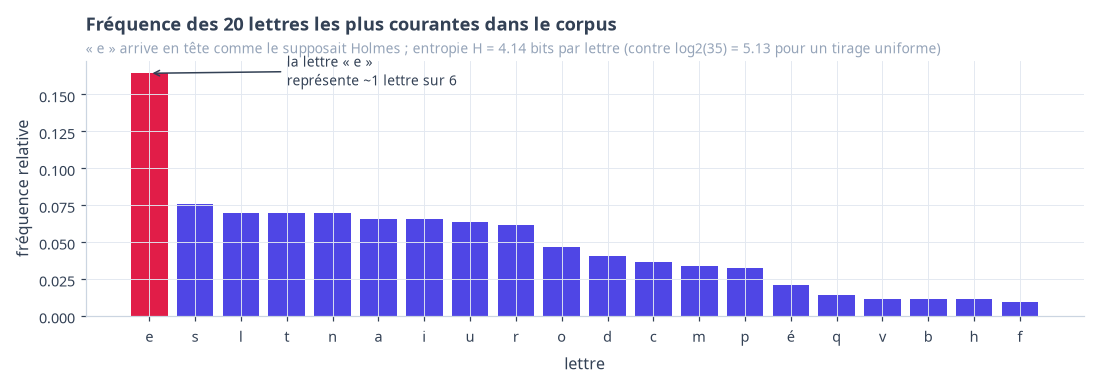

In [2]:
freqs = c1.letter_frequencies(c1.CORPUS_FR)
top = dict(list(freqs.items())[:20])
fig, ax = plt.subplots(figsize=(10, 3.6))
bars = ax.bar(list(top), list(top.values()), color=[ROSE if i == 0 else INDIGO for i in range(len(top))])
ax.set_ylabel("fréquence relative")
ax.set_xlabel("lettre")
H0 = c1.entropy(freqs)
c1.title_sub(ax, "Fréquence des 20 lettres les plus courantes dans le corpus", f"« e » arrive en tête comme le supposait Holmes ; entropie H = {H0:.2f} bits par lettre "
             f"(contre log2({len(freqs)}) = {np.log2(len(freqs)):.2f} pour un tirage uniforme)")
ax.annotate("la lettre « e »\nreprésente ~1 lettre sur 6", xy=(0, top["e"]), xytext=(3, top["e"] * 0.95),
            arrowprops=dict(arrowstyle="->", color=SLATE), fontsize=9)
plt.tight_layout(); plt.show()

**Entropie.** Shannon, dans l'article de 1951 cité par le livre (*Prediction and Entropy
of Printed English*), mesure l'information moyenne d'un symbole par l'**entropie**
$$H(p) = -\sum_i p_i \log_2 p_i \quad \text{(bits)}.$$
Elle vaut $\log_2 V$ pour une distribution uniforme sur $V$ symboles et $0$ si l'issue est
certaine. L'idée centrale de Shannon : **plus on connaît de contexte, plus la lettre
suivante est prévisible**, donc plus l'entropie *conditionnelle* $H(X_t \mid X_{t-k..t-1})$
baisse. Un modèle **n-gramme** de caractères ($k = n-1$ caractères de contexte) permet de
le voir, et de générer des « approximations » de plus en plus crédibles du français.

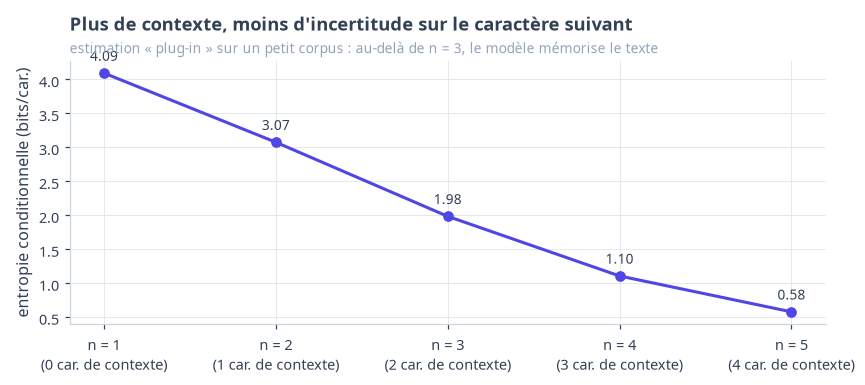

,ordre n,texte généré à partir de « le »
0,1,le csm ei r elemrvdnpd àdetmir pe ouandrqasoosert tei pdtdlenaarrluat vn
1,2,le chriche pale mouent à ete qure puendoratent qu s larduemenceront s à
2,3,le chochef de mentrasse à conne que une ques monst rique tours donst res
3,4,le bien de remierse imment rieurs briquest une mot soleille et du public
4,5,le matine début dune pendant le prend des briquestion traduire une début


In [3]:
text = c1.normalize_text(c1.CORPUS_FR)
orders = [1, 2, 3, 4, 5]
H = [c1.conditional_entropy(text, n) for n in orders]
samples = {n: "le " + c1.CharNGram(order=n, alpha=1e-4).fit(text).generate(70, prompt="le ", seed=3) for n in orders}

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(orders, H, "o-", color=INDIGO)
for n, h in zip(orders, H):
    ax.annotate(f"{h:.2f}", (n, h), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.set_xticks(orders, [f"n = {n}\n({n - 1} car. de contexte)" for n in orders])
ax.set_ylabel("entropie conditionnelle (bits/car.)")
c1.title_sub(ax, "Plus de contexte, moins d'incertitude sur le caractère suivant", "estimation « plug-in » sur un petit corpus : au-delà de n = 3, le modèle mémorise le texte")
plt.tight_layout(); plt.show()
pd.DataFrame({"ordre n": orders, "texte généré à partir de « le »": [samples[n] for n in orders]})

Avec $n = 1$ on obtient une soupe de lettres aux bonnes fréquences ; à $n = 3$ des
syllabes et de vrais petits mots apparaissent ; à $n = 5$ des morceaux entiers du
corpus ressortent, car un si petit texte ne contient presque qu'une seule suite possible
pour chaque contexte de 4 caractères. C'est le dilemme fondamental de la modélisation
du langage : **un long contexte est nécessaire, mais le nombre de contextes possibles
explose** ($V^{k}$ pour $k$ symboles de contexte). Les réseaux de neurones (et en
particulier les transformers) résolvent ce problème en **partageant** l'information entre
contextes similaires au lieu de les compter un par un.

Faisons le même test qu'au début de la section *Language models* avec un vrai modèle
neuronal, GPT-2 (124 M paramètres) : après « My favorite color is », le mot « blue »
doit être bien plus probable que « car ».

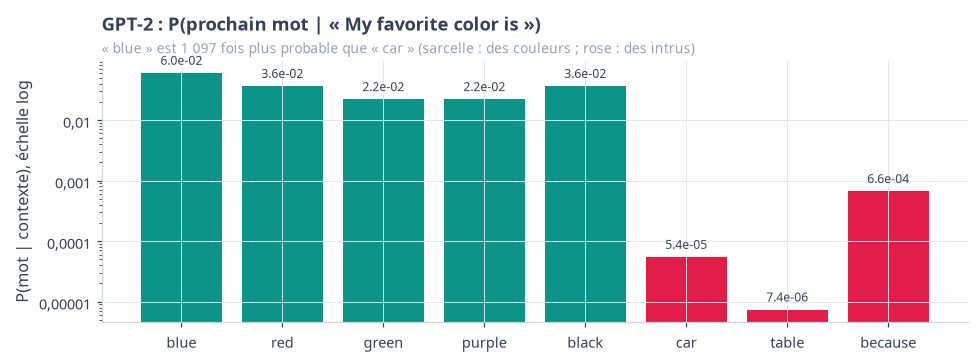

In [4]:
logits = llm.full_logits("My favorite color is", llm.BASE)
probs = llm.softmax(logits)
tok_gpt2, _ = llm.load(llm.BASE)
cands = [" blue", " red", " green", " purple", " black", " car", " table", " because"]
p_c = [probs[tok_gpt2.encode(w)[0]] for w in cands]

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar([w.strip() for w in cands], p_c, color=[TEAL] * 5 + [ROSE] * 3)
ax.set_yscale("log"); c1.plain_log(ax, "y")
ax.set_ylabel("P(mot | contexte), échelle log")
ratio_bc = f"{p_c[0] / p_c[5]:,.0f}".replace(",", " ")
c1.title_sub(ax, "GPT-2 : P(prochain mot | « My favorite color is »)",
             f"« blue » est {ratio_bc} fois plus probable que « car » (sarcelle : des couleurs ; rose : des intrus)")
annotate_bars(ax, "{:.1e}", fontsize=8)
plt.tight_layout(); plt.show()

> **À retenir.** Un modèle de langage est une distribution $P(x_t \mid x_{<t})$ sur l'unité
> suivante. Plus il exploite de contexte, plus son entropie (son incertitude) baisse :
> c'est l'intuition de Shannon, que les LLM poussent à l'extrême avec des contextes de
> milliers de tokens.

## 2. Tokens, tokenisation et vocabulaire (section *Language models*)

**Définitions.** L'unité de base d'un modèle de langage est le **token** : un caractère,
un mot ou un morceau de mot selon le modèle. La **tokenisation** découpe le texte en
tokens, chacun identifié par un entier ; l'ensemble des tokens possibles forme le
**vocabulaire** (de taille $V$). Le livre donne l'exemple de GPT-4, qui coupe « can't »
en deux tokens. Comparons cinq tokenizers réels sur une même phrase :

| tokenizer | modèles | algorithme |
|---|---|---|
| GPT-2 | GPT-2, GPT-3 | BPE sur octets, ~50 k tokens |
| cl100k | GPT-3.5, GPT-4 | BPE sur octets, ~100 k |
| o200k | GPT-4o | BPE sur octets, ~200 k, plus multilingue |
| Qwen2.5 | famille Qwen | BPE sur octets, ~151 k |
| XLM-R | XLM-RoBERTa (BERT multilingue) | SentencePiece unigramme, ~250 k |

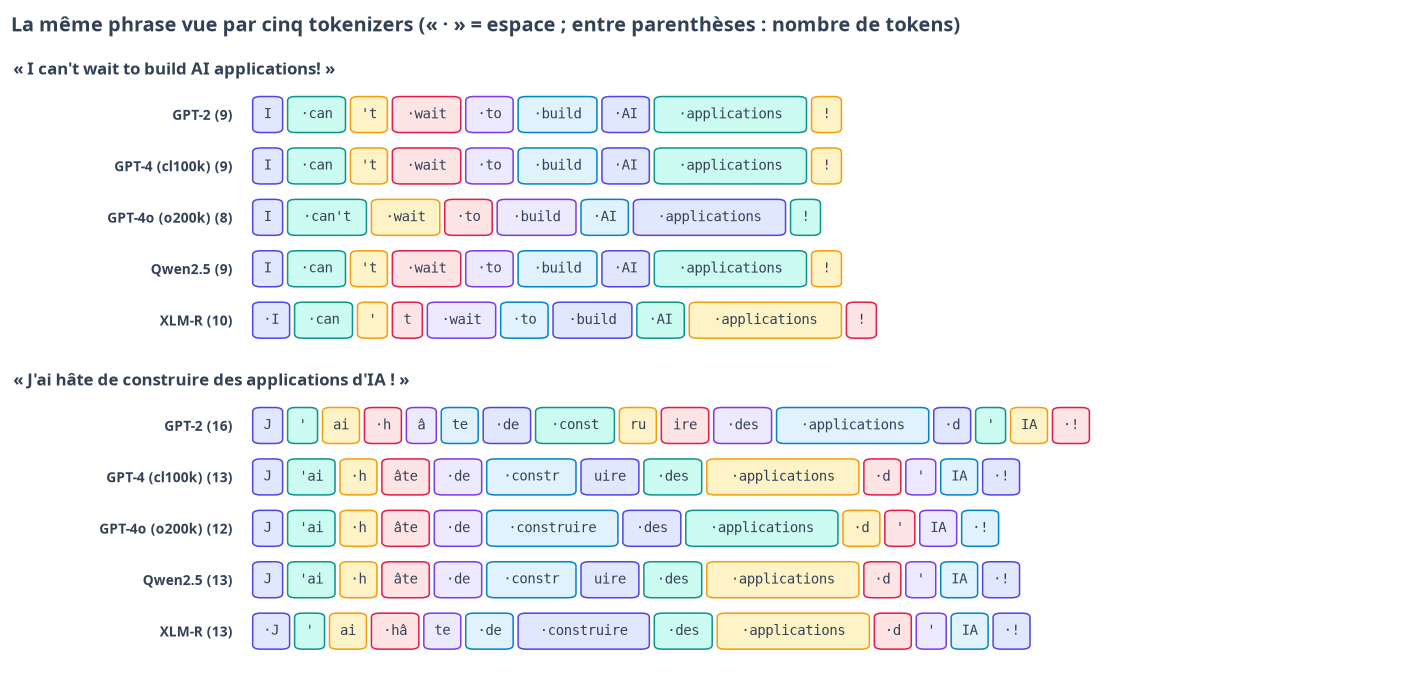

In [5]:
phrases = ["I can't wait to build AI applications!",
           "J'ai hâte de construire des applications d'IA !"]
names = list(c1.TOKENIZERS)
fig, axes = plt.subplots(2, 1, figsize=(13, 6.2))
for ax, ph in zip(axes, phrases):
    for i, n in enumerate(names):
        tk = c1.get_tokenizer(n)
        pcs = tk.pieces(ph)
        c1.draw_tokens(ax, pcs, y=-i, x0=2.4, fontsize=9, char_w=0.105, label=f"{n} ({len(pcs)})")
    ax.set_xlim(0, 14); ax.set_ylim(-len(names) + 0.4, 0.6)
    ax.axis("off")
    ax.set_title(f"« {ph} »", fontsize=11)
finish(fig, "La même phrase vue par cinq tokenizers (« · » = espace ; entre parenthèses : nombre de tokens)")
plt.show()

Quelques observations :

- l'espace fait **partie** du token qui suit (« ·build ») : c'est la convention des BPE
  de type GPT-2 ; SentencePiece (XLM-R) fait de même avec son symbole « ▁ » ;
- en anglais, tous les tokenizers donnent à peu près un token par mot ;
- en français, le tokenizer de GPT-2, appris sur un web essentiellement anglophone,
  **émiette** les mots (« h », « â », « te ») : le même message coûte plus de tokens ;
- les tokenizers plus récents, à vocabulaire plus grand, compressent mieux le français.

**Taille du vocabulaire et ratio mots / tokens.** Le livre indique que pour GPT-4 un token
vaut en moyenne les trois quarts d'un mot (100 tokens ≈ 75 mots). Vérifions-le sur notre
petit corpus anglais.

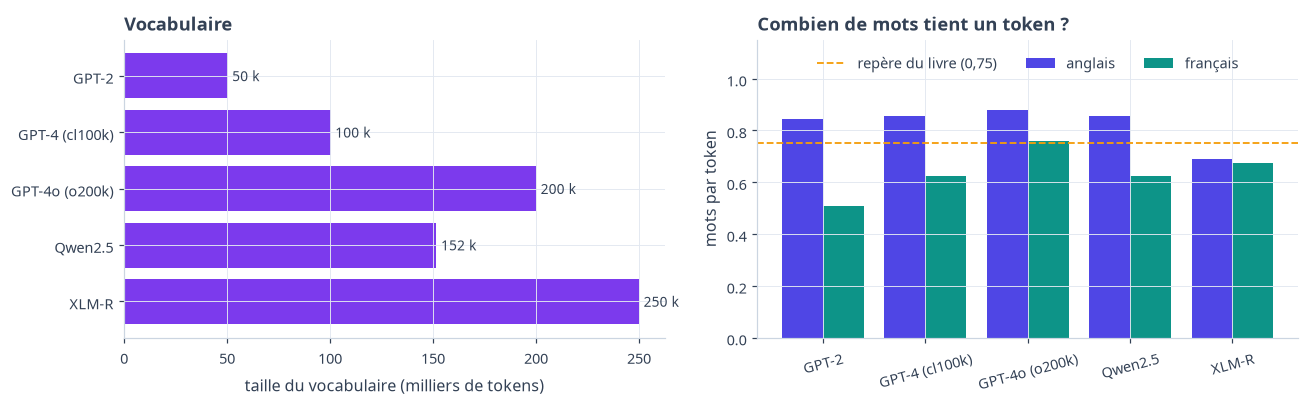

,taille du vocabulaire,mots / token (anglais),mots / token (français)
tokenizer,,,
GPT-2,50257,0.84,0.51
GPT-4 (cl100k),100277,0.86,0.62
GPT-4o (o200k),200019,0.88,0.76
Qwen2.5,151665,0.86,0.62
XLM-R,250002,0.69,0.68


In [6]:
en_text = " ".join(e for e, _ in c1.PARALLEL_EN_FR)
fr_text = " ".join(f for _, f in c1.PARALLEL_EN_FR)
rows = []
for n in names:
    tk = c1.get_tokenizer(n)
    rows.append({"tokenizer": n, "taille du vocabulaire": tk.vocab_size,
                 "mots / token (anglais)": len(c1.words(en_text)) / tk.count(en_text),
                 "mots / token (français)": len(c1.words(fr_text)) / tk.count(fr_text)})
voc = pd.DataFrame(rows).set_index("tokenizer")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].barh(voc.index[::-1], voc["taille du vocabulaire"][::-1] / 1000, color=VIOLET)
axes[0].set_xlabel("taille du vocabulaire (milliers de tokens)")
axes[0].set_title("Vocabulaire")
annotate_bars(axes[0], "{:.0f} k")
x = np.arange(len(voc))
axes[1].bar(x - 0.2, voc["mots / token (anglais)"], 0.4, color=INDIGO, label="anglais")
axes[1].bar(x + 0.2, voc["mots / token (français)"], 0.4, color=TEAL, label="français")
axes[1].axhline(0.75, color=AMBER, ls="--", lw=1.2, label="repère du livre (0,75)")
axes[1].set_ylim(0, 1.15)
axes[1].set_xticks(x, voc.index, rotation=15)
axes[1].set_ylabel("mots par token")
axes[1].set_title("Combien de mots tient un token ?")
axes[1].legend(loc="upper center", ncol=3)
finish(fig); plt.show()
voc.round(2)

Sur nos phrases courtes (beaucoup de ponctuation, d'apostrophes), on obtient un peu moins
de 0,75 mot par token en anglais ; l'ordre de grandeur du livre est le bon. En français,
un token « vaut » nettement moins d'un mot pour GPT-2, et l'écart se resserre avec les
vocabulaires récents.

> **À retenir.** Le token est l'unité de calcul **et** de facturation d'un LLM. La même
> phrase ne coûte pas le même nombre de tokens selon le tokenizer : il faut toujours
> compter avec le tokenizer du modèle réellement utilisé.

## 3. Pourquoi des sous-mots ? (encadré sur les tokens, section *Language models*)

Le livre donne trois raisons de préférer les tokens aux caractères ou aux mots : les
sous-mots portent du sens (« cook » + « ing »), un vocabulaire plus petit que celui des
mots rend le modèle plus efficace, et les mots inconnus restent représentables
(« chatgpting »). Rendons ces trois arguments **quantitatifs**.

**L'algorithme BPE** (*Byte Pair Encoding*, Sennrich et al. 2016) construit le
vocabulaire de façon gloutonne :

1. partir des caractères (ou des 256 octets) comme symboles de base ;
2. compter toutes les paires de symboles adjacents dans le corpus ;
3. fusionner la paire la plus fréquente en un nouveau symbole, l'ajouter au vocabulaire ;
4. recommencer jusqu'à atteindre la taille de vocabulaire voulue.

On l'a écrit en 30 lignes dans `aie/ch01_introduction.py` (`train_bpe`, `bpe_tokenize`).
Le symbole « _ » marque la fin d'un mot.

In [7]:
corpus_words = c1.words(c1.CORPUS_FR.lower())
merges = c1.train_bpe(corpus_words, 300)
pd.DataFrame({"étape": range(1, 13), "paire fusionnée": [f"{a} + {b}" for a, b in merges[:12]],
              "nouveau symbole": [a + b for a, b in merges[:12]]}).set_index("étape").T

étape,1,2,3,4,5,6,7,8,9,10,11,12
paire fusionnée,e + _,s + _,t + _,e + n,l + e_,e + s_,q + u,o + n,d + e_,a + n,en + t_,i + l
nouveau symbole,e_,s_,t_,en,le_,es_,qu,on,de_,an,ent_,il


Les premières fusions capturent les suites les plus fréquentes du français : finales de
mots (« e_ », « s_ »), articles, terminaisons. Appliquons ce BPE (appris sur notre seul
petit corpus) à des mots, dont certains **n'y figurent pas** :

In [8]:
test_words = ["construire", "démonstration", "reconstruire", "chatgptiser", "anticonstitutionnellement"]
rows = []
for w in test_words:
    rows.append({"mot": w, "dans le corpus ?": "oui" if w in corpus_words else "non",
                 "BPE maison (300 fusions)": " | ".join(c1.bpe_tokenize(w, merges)),
                 "GPT-4o (o200k)": " | ".join(c1.get_tokenizer("GPT-4o (o200k)").pieces(" " + w)).strip()})
pd.DataFrame(rows)

,mot,dans le corpus ?,BPE maison (300 fusions),GPT-4o (o200k)
0,construire,oui,construire_,construire
1,démonstration,oui,démonstration_,démon | str | ation
2,reconstruire,non,re | construire_,reconstru | ire
3,chatgptiser,non,ch | at | g | p | ti | s | er_,chat | g | pt | iser
4,anticonstitutionnellement,non,an | ti | const | i | t | u | ti | on | n | el | l | ement_,anticon | stitution | nel | lement


« reconstruire » n'apparaît pas dans le corpus mais se décompose en morceaux connus,
dont une partie de « construire » : le modèle pourra exploiter ce qu'il sait du mot
racine. Aucun mot n'est jamais « hors vocabulaire » puisqu'on peut toujours redescendre
aux caractères (ou aux octets, pour les BPE au niveau des octets).

**Le compromis vocabulaire / longueur de séquence.** Un vocabulaire de caractères est
minuscule mais produit des séquences très longues (coûteuses : le coût de l'attention
croît comme le carré de la longueur, cf. chapitre 2). Un vocabulaire de mots donne des
séquences courtes mais énormes en taille, et ne sait pas traiter un mot nouveau. BPE
parcourt continûment le chemin entre les deux. Mesurons-le, ainsi que le taux de mots
inconnus d'un vocabulaire de mots appris sur la première moitié du corpus.

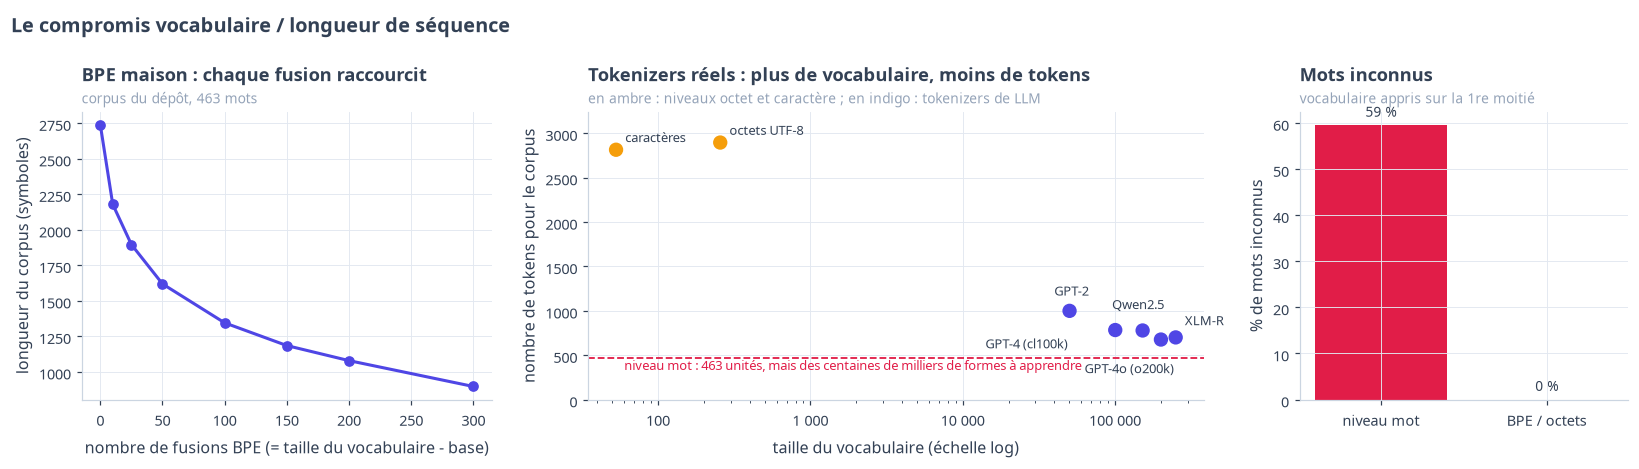

In [9]:
merge_grid = [0, 10, 25, 50, 100, 150, 200, 300]
all_merges = c1.train_bpe(corpus_words, max(merge_grid))
bpe_len = [sum(len(c1.bpe_tokenize(w, all_merges[:m])) for w in corpus_words) for m in merge_grid]

# tokenizers réels sur le même texte, du niveau octet au niveau mot
real = [("octets UTF-8", 256, len(c1.CORPUS_FR.encode("utf-8"))),
        ("caractères", len(set(c1.CORPUS_FR)), len(c1.CORPUS_FR))]
real += [(n, c1.get_tokenizer(n).vocab_size, c1.get_tokenizer(n).count(c1.CORPUS_FR)) for n in names]
n_words = len(c1.words(c1.CORPUS_FR))

half = len(corpus_words) // 2
train_vocab = set(corpus_words[:half])
oov = np.mean([w not in train_vocab for w in corpus_words[half:]])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1, 1.5, 0.8]})
ax = axes[0]
ax.plot(merge_grid, bpe_len, "o-", color=INDIGO)
ax.set_xlabel("nombre de fusions BPE (= taille du vocabulaire - base)")
ax.set_ylabel("longueur du corpus (symboles)")
c1.title_sub(ax, "BPE maison : chaque fusion raccourcit", f"corpus du dépôt, {len(corpus_words)} mots")
ax = axes[1]
labels, V, L = zip(*real)
cols = [AMBER, AMBER] + [INDIGO] * len(names)
ax.scatter(V, L, s=70, color=cols, zorder=5)
offsets = {"GPT-2": (-10, 10), "GPT-4 (cl100k)": (-85, -12), "Qwen2.5": (-20, 14),
           "GPT-4o (o200k)": (-50, -22), "XLM-R": (6, 8)}
for lb, v, l in zip(labels, V, L):
    ax.annotate(lb, (v, l), textcoords="offset points", xytext=offsets.get(lb, (6, 5)), fontsize=8.5)
ax.axhline(n_words, color=ROSE, ls="--", lw=1.2)
ax.text(60, n_words * 0.72, f"niveau mot : {n_words} unités, mais des centaines de milliers de formes à apprendre",
        color=ROSE, fontsize=8.5)
ax.set_xscale("log"); c1.plain_log(ax, "x"); ax.set_ylim(0, max(L) * 1.12)
ax.set_xlabel("taille du vocabulaire (échelle log)")
ax.set_ylabel("nombre de tokens pour le corpus")
c1.title_sub(ax, "Tokenizers réels : plus de vocabulaire, moins de tokens",
             "en ambre : niveaux octet et caractère ; en indigo : tokenizers de LLM")
axes[2].bar(["niveau mot", "BPE / octets"], [oov * 100, 0], color=[ROSE, TEAL])
axes[2].set_ylabel("% de mots inconnus")
c1.title_sub(axes[2], "Mots inconnus", "vocabulaire appris sur la 1re moitié")
annotate_bars(axes[2], "{:.0f} %")
finish(fig, "Le compromis vocabulaire / longueur de séquence"); plt.show()

Le niveau octet est imbattable en taille de vocabulaire (256) mais produit des séquences
environ quatre fois plus longues qu'un tokenizer de LLM. Le niveau mot donnerait les
séquences les plus courtes, au prix d'un vocabulaire gigantesque. Les concepteurs
choisissent un point de compromis (32 k pour Mixtral, ~100 k pour GPT-4,
~150 k à 250 k pour les modèles très multilingues). Avec un vocabulaire de mots, une
grosse fraction des mots de la seconde moitié du corpus serait inconnue (graphique de
droite) : c'est le défaut rédhibitoire que la tokenisation en sous-mots élimine.

> **À retenir.** Les sous-mots sont un compromis : assez gros pour porter du sens et
> raccourcir les séquences, assez petits pour que le vocabulaire reste raisonnable et que
> tout mot (même inventé) reste représentable.

## 4. Le coût en tokens dépend de la langue (section *Language models*, note 2)

Une note du livre signale que, pour les langues autres que l'anglais, un seul caractère
Unicode peut nécessiter plusieurs tokens. La raison : les BPE modernes travaillent sur les
**octets** UTF-8. Un caractère accentué occupe 2 octets, un caractère chinois 3, un
caractère devanagari 3 ; si une suite d'octets n'a pas été fusionnée pendant
l'apprentissage (car rare dans le corpus), elle reste éclatée. Le symbole « � » ci-dessous
signale un token qui ne contient qu'**un morceau** de caractère.

In [10]:
for n in ["GPT-2", "GPT-4o (o200k)"]:
    tk = c1.get_tokenizer(n)
    for w in ["hâte", "今天天气", "मौसम"]:
        print(f"{n:15s} {w!r:12s} {len(w.encode('utf-8')):2d} octets -> {tk.pieces(w)}")

GPT-2           'hâte'        5 octets -> ['h', 'â', 'te']
GPT-2           '今天天气'       12 octets -> ['�', '�', '天', '天', '�', '�']
GPT-2           'मौसम'       12 octets -> ['�', '�', '�', '�', '�', '�', '�', '�']
GPT-4o (o200k)  'hâte'        5 octets -> ['h', 'âte']
GPT-4o (o200k)  '今天天气'       12 octets -> ['今', '天天', '气']
GPT-4o (o200k)  'मौसम'       12 octets -> ['म', 'ौ', 'सम']


Mesurons la « taxe » linguistique : nombre de tokens d'une même phrase traduite dans sept
langues, rapporté au nombre de tokens de la version anglaise.

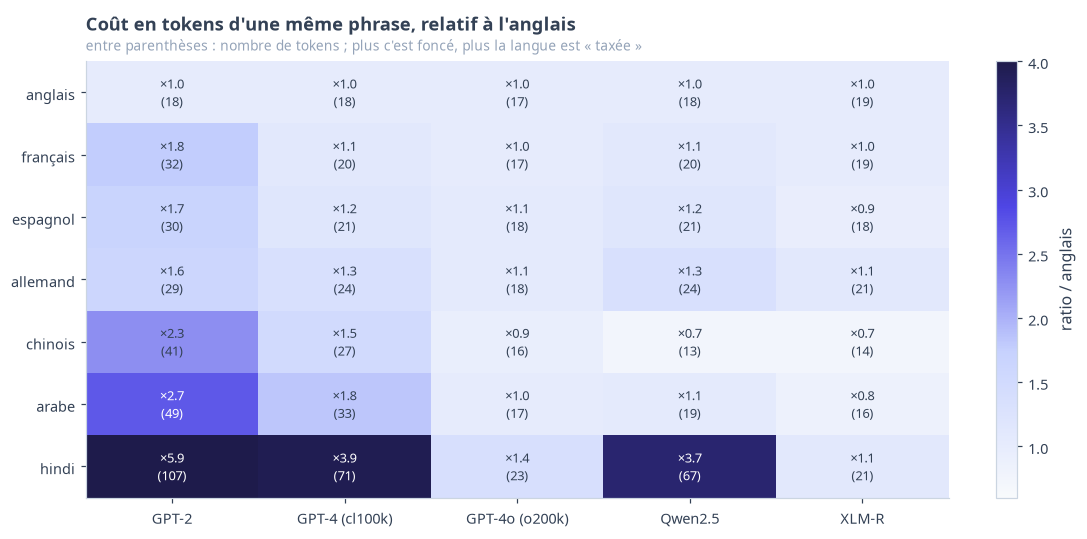

In [11]:
counts = c1.compare_tokenizers(c1.PARALLEL)
ratio = counts / counts.loc["anglais"]
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(ratio.values, cmap="aie_seq", vmin=0.6, vmax=4, aspect="auto")
ax.set_xticks(range(len(ratio.columns)), ratio.columns)
ax.set_yticks(range(len(ratio.index)), ratio.index)
ax.grid(False)
for i in range(ratio.shape[0]):
    for j in range(ratio.shape[1]):
        val = ratio.values[i, j]
        ax.text(j, i, f"×{val:.1f}\n({counts.values[i, j]})", ha="center", va="center", fontsize=8.5,
                color="white" if val > 2.3 else SLATE)
c1.title_sub(ax, "Coût en tokens d'une même phrase, relatif à l'anglais", "entre parenthèses : nombre de tokens ; plus c'est foncé, plus la langue est « taxée »")
plt.colorbar(im, ax=ax, fraction=0.03, label="ratio / anglais")
plt.tight_layout(); plt.show()

Le constat est frappant : pour GPT-2, la phrase en hindi coûte environ **six fois** plus
de tokens qu'en anglais, et le français presque deux fois plus. Les vocabulaires récents
et multilingues (o200k, XLM-R) ramènent la plupart des langues près de l'anglais. Les
conséquences sont très concrètes pour l'ingénieur d'application :

- **coût** : la facturation se fait au token ;
- **latence** : chaque token de sortie est un pas de génération ;
- **contexte** : une fenêtre de 8 k tokens contient moins de texte hindi qu'anglais.

> **À retenir.** Comptez les tokens dans la langue de vos utilisateurs, avec le tokenizer
> de votre modèle : la même application peut coûter deux à six fois plus cher selon la
> langue (l'exercice 1.1 approfondit ce point).

## 5. Modèles masqués et autorégressifs (section *Language models*)

Les deux grandes familles se distinguent par **l'information qu'elles voient** pour prédire
un token :

- un **modèle masqué** (BERT, RoBERTa) remplit des trous n'importe où dans la séquence, en
  regardant le contexte **avant et après** le trou ;
- un **modèle autorégressif** (ou causal : GPT, Llama, Qwen) prédit le token **suivant**
  en ne regardant que ce qui précède ; il peut donc générer indéfiniment, token après
  token.

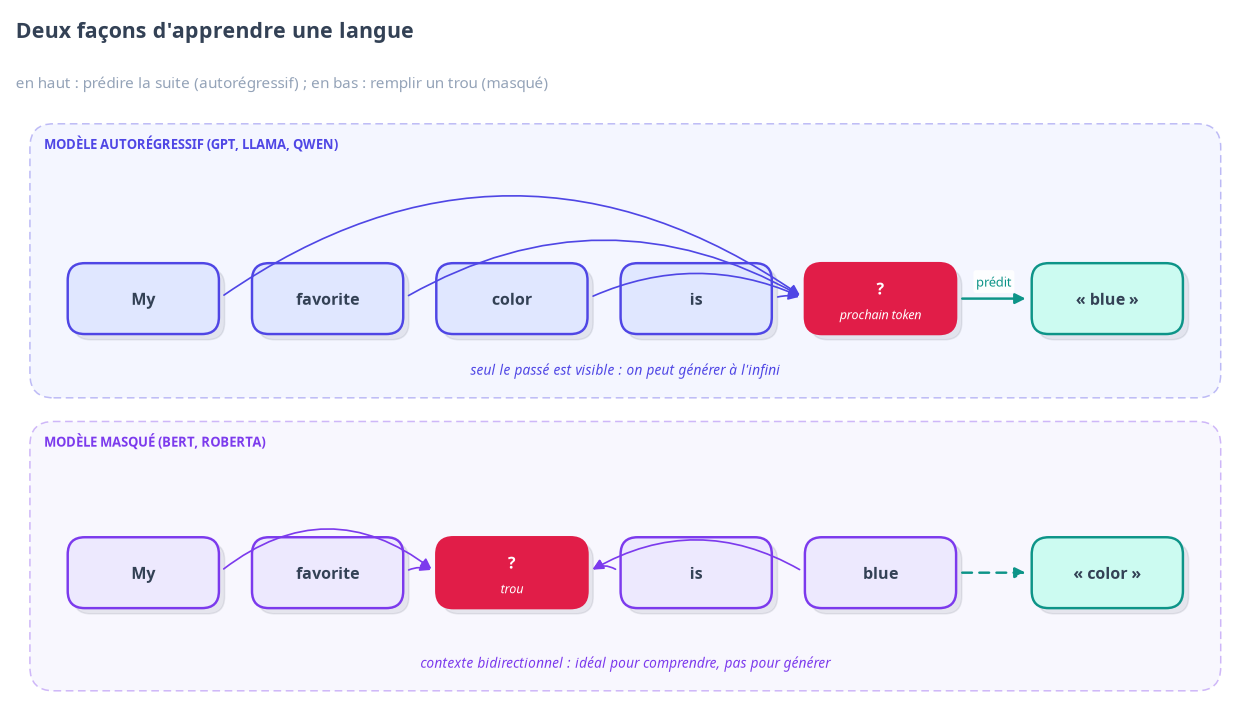

In [12]:
d = Diagram(13, 6.4, title="Deux façons d'apprendre une langue",
            subtitle="en haut : prédire la suite (autorégressif) ; en bas : remplir un trou (masqué)")
toks_ar = ["My", "favorite", "color", "is"]
d.group(0.2, 3.25, 12.8, 6.15, "Modèle autorégressif (GPT, Llama, Qwen)", INDIGO)
for i, t in enumerate(toks_ar):
    d.box(f"a{i}", 1.4 + i * 1.95, 4.3, t, color=INDIGO, w=1.6, h=0.75)
d.box("a4", 1.4 + 4 * 1.95, 4.3, "?", sub="prochain token", color=ROSE, w=1.6, h=0.75, filled=True)
d.box("ap", 11.6, 4.3, "« blue »", color=TEAL, w=1.6, h=0.75)
for i in range(4):
    d.arrow(f"a{i}", "a4", rad=-0.35 + 0.06 * i, color=INDIGO, lw=1.1)
d.arrow("a4", "ap", "prédit", color=TEAL)
d.note(6.5, 3.55, "seul le passé est visible : on peut générer à l'infini", color=INDIGO)

toks_m = ["My", "favorite", "[MASK]", "is", "blue"]
d.group(0.2, 0.15, 12.8, 3.0, "Modèle masqué (BERT, RoBERTa)", VIOLET)
for i, t in enumerate(toks_m):
    if t == "[MASK]":
        d.box(f"m{i}", 1.4 + i * 1.95, 1.4, "?", sub="trou", color=ROSE, w=1.6, h=0.75, filled=True)
    else:
        d.box(f"m{i}", 1.4 + i * 1.95, 1.4, t, color=VIOLET, w=1.6, h=0.75)
d.box("mp", 11.6, 1.4, "« color »", color=TEAL, w=1.6, h=0.75)
for i in [0, 1]:
    d.arrow(f"m{i}", "m2", rad=-0.4 + 0.1 * i, color=VIOLET, lw=1.1)
for i in [3, 4]:
    d.arrow(f"m{i}", "m2", rad=0.4 - 0.1 * (i - 3), color=VIOLET, lw=1.1)
d.arrow("m4", "mp", color=TEAL, style="dashed")
d.note(6.5, 0.45, "contexte bidirectionnel : idéal pour comprendre, pas pour générer", color=VIOLET)
d.show()

**Formalisation par les masques d'attention.** Dans un transformer, la différence se
résume à une matrice binaire $M$ : le token $i$ peut « regarder » le token $j$ si
$M_{ij} = 1$. Un modèle causal impose $M_{ij} = 1 \iff j \le i$ (matrice triangulaire
inférieure) ; un modèle masqué laisse tout visible, sauf que certains tokens d'entrée
ont été remplacés par `[MASK]`. L'objectif d'apprentissage diffère en conséquence :
$$\mathcal L_{\text{AR}} = -\sum_{t} \log P(x_t \mid x_{<t}), \qquad
  \mathcal L_{\text{MLM}} = -\sum_{t \in \mathcal M} \log P(x_t \mid x_{\setminus \mathcal M}),$$
où $\mathcal M$ est l'ensemble des positions masquées (environ 15 % chez BERT).

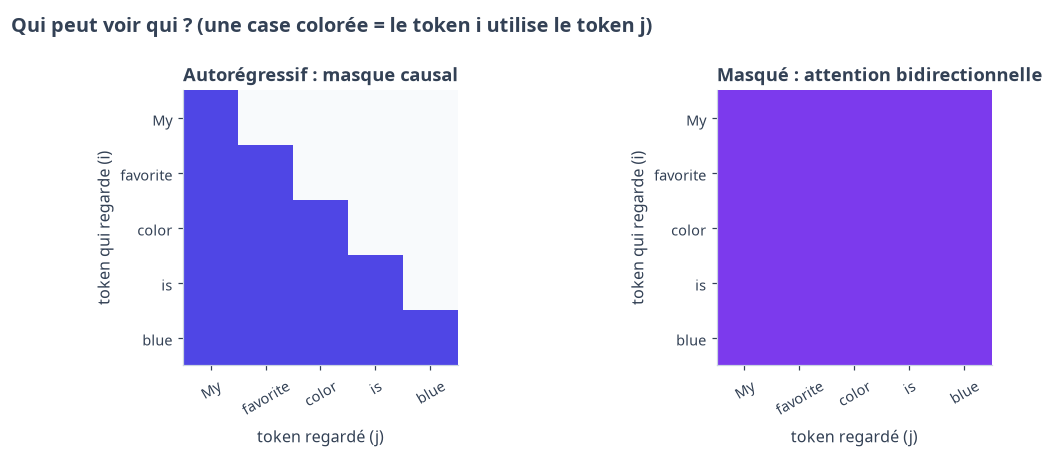

In [13]:
lab = ["My", "favorite", "color", "is", "blue"]
causal = np.tril(np.ones((5, 5)))
bidir = np.ones((5, 5))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, M, ttl, col in [(axes[0], causal, "Autorégressif : masque causal", INDIGO),
                        (axes[1], bidir, "Masqué : attention bidirectionnelle", VIOLET)]:
    from matplotlib.colors import ListedColormap
    ax.imshow(M, cmap=ListedColormap(["#F8FAFC", col]), vmin=0, vmax=1)
    ax.set_xticks(range(5), lab, rotation=30); ax.set_yticks(range(5), lab)
    ax.set_xlabel("token regardé (j)"); ax.set_ylabel("token qui regarde (i)")
    ax.set_title(ttl); ax.grid(False)
finish(fig, "Qui peut voir qui ? (une case colorée = le token i utilise le token j)")
plt.show()

**Expérience.** Posons la question des deux façons : à un petit modèle masqué
(DistilRoBERTa, 82 M paramètres) le trou « My favorite ___ is blue. », et à GPT-2 la
suite de « My favorite color is ».

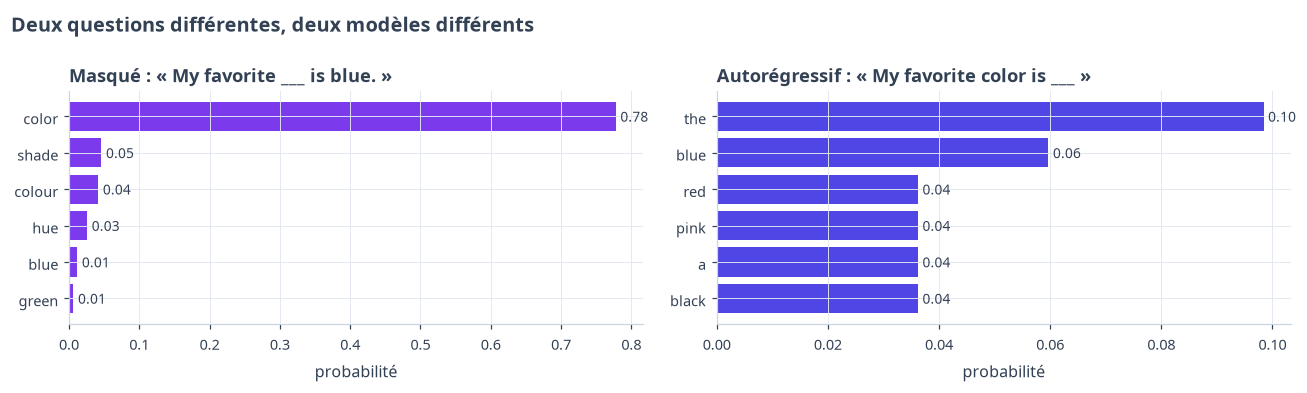

In [14]:
from transformers import pipeline
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error(); hf_logging.disable_progress_bar()
fill = pipeline("fill-mask", model="distilbert/distilroberta-base", device=llm.device())
mlm = fill("My favorite <mask> is blue.", top_k=6)
ar = llm.next_token_distribution("My favorite color is", llm.BASE, k=6)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].barh([r["token_str"].strip() for r in mlm][::-1], [r["score"] for r in mlm][::-1], color=VIOLET)
axes[0].set_title("Masqué : « My favorite ___ is blue. »")
axes[0].set_xlabel("probabilité")
axes[1].barh([t.strip() for t in ar.tokens][::-1], ar.probs[::-1], color=INDIGO)
axes[1].set_title("Autorégressif : « My favorite color is ___ »")
axes[1].set_xlabel("probabilité")
for ax in axes:
    annotate_bars(ax, "{:.2f}")
finish(fig, "Deux questions différentes, deux modèles différents"); plt.show()

Le modèle masqué exploite « is blue » situé **après** le trou pour deviner « color » avec
une forte confiance ; le modèle autorégressif, qui ne voit que le passé, répartit sa
probabilité entre des couleurs et des mots grammaticaux (« the », « a ») : la suite est
réellement incertaine, aucune réponse n'est « la » bonne. Le
livre note que les modèles masqués servent surtout aux tâches **non génératives**
(classification, analyse de sentiment, embeddings), tandis que les modèles
autorégressifs dominent la génération ; dans la suite du livre et de ces notebooks,
« modèle de langage » désigne un modèle autorégressif.

> **À retenir.** Masqué = remplir un trou avec le contexte des deux côtés (comprendre) ;
> autorégressif = prédire la suite avec le seul passé (générer). Techniquement, tout tient
> dans le masque d'attention et dans l'objectif d'apprentissage.

## 6. Le modèle de langage comme machine à compléter (section *Language models*)

**La boucle de génération.** Un modèle autorégressif produit une distribution sur le
prochain token ; on en choisit un (ici le plus probable : décodage *glouton*), on
l'ajoute au texte, et on recommence. Le texte produit est **ouvert** : un vocabulaire fini
permet de construire une infinité de sorties, d'où le terme d'IA **générative**.
Observons cette boucle pas à pas avec GPT-2.

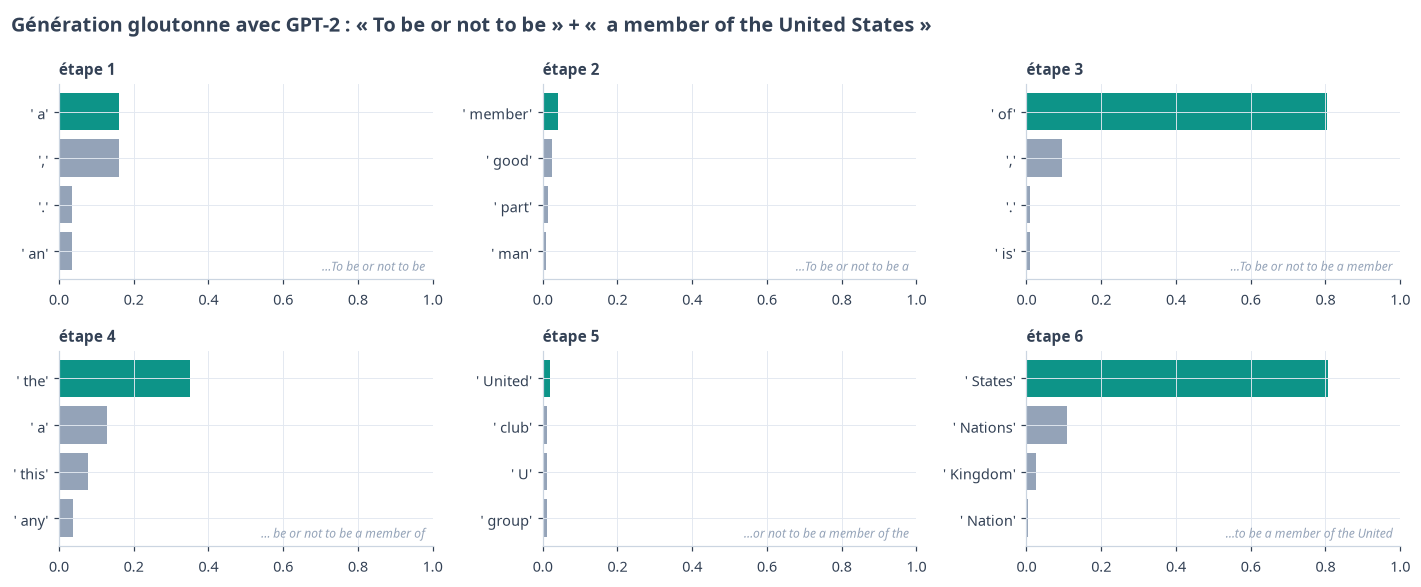

In [15]:
ctx = "To be or not to be"
steps = []
for _ in range(6):
    nt = llm.next_token_distribution(ctx, llm.BASE, k=4)
    steps.append((ctx, nt))
    ctx = ctx + nt.tokens[0]

fig, axes = plt.subplots(2, 3, figsize=(13, 5.4))
for k, (ax, (c, nt)) in enumerate(zip(axes.ravel(), steps)):
    colors = [TEAL] + [GRAY] * 3
    ax.barh([repr(t) for t in nt.tokens][::-1], nt.probs[::-1], color=colors[::-1])
    ax.set_xlim(0, 1)
    ax.set_title(f"étape {k + 1}", fontsize=10)
    ax.text(0.98, 0.04, "…" + c[-28:], transform=ax.transAxes, ha="right", fontsize=8, color=GRAY, style="italic")
finish(fig, f"Génération gloutonne avec GPT-2 : « To be or not to be » + « {ctx[len('To be or not to be'):]} »")
plt.show()

Surprise : GPT-2 ne récite **pas** Hamlet. Au premier pas, « a » et « , » sont à égalité
(environ 16 % chacun) ; le décodage glouton prend « a » et la suite part dans une tout
autre direction, chaque token rendant le suivant plus probable (« member of the United
States »). Deux leçons : une complétion est une **prédiction probabiliste**, pas une
connaissance garantie ; et une petite différence au début peut changer toute la suite.
La capacité à mémoriser une citation dépend aussi de la taille du modèle :


In [16]:
hamlet = {m: llm.complete("To be or not to be", mid, max_new_tokens=8).replace("\n", " ").replace("\xa0", " ")
          for m, mid in [("GPT-2 (124 M)", llm.BASE), ("Qwen2.5-0.5B (494 M)", llm.SMALL),
                         ("Qwen2.5-1.5B (1,5 Md)", llm.MEDIUM)]}
llm.free_gpu()  # libère le modèle 1,5 Md (GPU partagé)
pd.DataFrame({"modèle": list(hamlet), "complétion gloutonne de « To be or not to be »": list(hamlet.values())})

,modèle,complétion gloutonne de « To be or not to be »
0,GPT-2 (124 M),", the only thing that matters is that"
1,Qwen2.5-0.5B (494 M),: the role of the teacher
2,"Qwen2.5-1.5B (1,5 Md)",: that is the question. What does


(Avec `generate`, l'égalité du premier pas est départagée autrement : GPT-2 part sur
« , the only thing that matters... » ; dans les deux cas, pas de Hamlet.) Seul le plus
gros des trois modèles retrouve la réplique attendue (« : that is the question ») : la mémorisation de faits précis croît avec la taille,
un premier aperçu de l'importance de l'**échelle** (cours 2).

**Toute tâche est une complétion.** En formulant bien le début du texte, on transforme le
modèle en traducteur ou en classifieur, sans aucun réentraînement. Testons deux gabarits
de complétion brute (sans gabarit de conversation) sur Qwen2.5-0.5B.

Traduction  « English: How are you?\nFrench: »  -> 'Comment ça va ?'


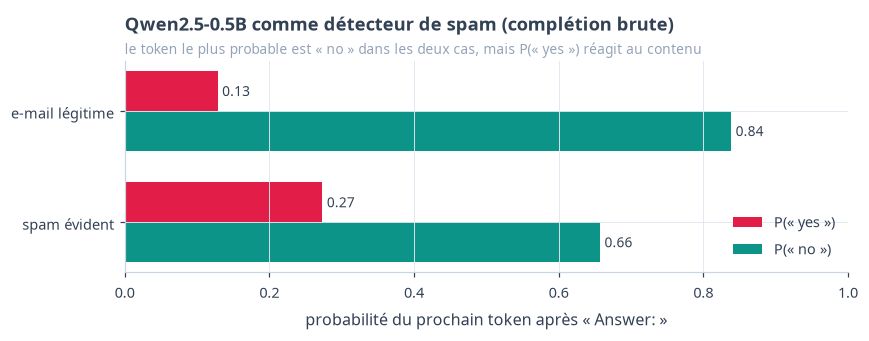

In [17]:
trad = llm.complete("English: How are you?\nFrench:", llm.SMALL, max_new_tokens=8).strip().split("\n")[0]
print("Traduction  « English: How are you?\\nFrench: »  ->", repr(trad))

emails = {"spam évident": "Congratulations! You won a free iPhone, click here to claim your prize now!!!",
          "e-mail légitime": "Hi Paul, the meeting is moved to 3pm tomorrow, see you there."}
tok_q, _ = llm.load(llm.SMALL)
ids = lambda words_: [tok_q.encode(w)[0] for w in words_]
res = {}
for k, e in emails.items():
    p = llm.softmax(llm.full_logits(f"Email: {e}\nQuestion: Is this email spam? Answer yes or no.\nAnswer:", llm.SMALL))
    res[k] = (p[ids([" Yes", " yes"])].sum(), p[ids([" No", " no"])].sum())

fig, ax = plt.subplots(figsize=(8, 3.2))
yv = np.arange(len(res))
ax.barh(yv + 0.18, [v[0] for v in res.values()], 0.36, color=ROSE, label="P(« yes »)")
ax.barh(yv - 0.18, [v[1] for v in res.values()], 0.36, color=TEAL, label="P(« no »)")
ax.set_yticks(yv, list(res)); ax.set_xlim(0, 1)
ax.set_xlabel("probabilité du prochain token après « Answer: »")
annotate_bars(ax, "{:.2f}")
ax.legend(loc="lower right")
c1.title_sub(ax, "Qwen2.5-0.5B comme détecteur de spam (complétion brute)",
             "le token le plus probable est « no » dans les deux cas, mais P(« yes ») réagit au contenu")
plt.tight_layout(); plt.show()

La traduction fonctionne directement. Pour le spam, le résultat est instructif : en
décodage glouton, ce petit modèle répond « no » aux **deux** e-mails (un classifieur
inutilisable en l'état). Pourtant, la probabilité de « yes » est environ deux fois plus
forte pour le spam : l'information est présente dans la distribution, mais pas assez pour
changer le token le plus probable. On pourrait comparer P(« yes ») à un seuil calibré sur
quelques exemples, améliorer le prompt, ou prendre un modèle plus gros. Le même modèle
sert donc de traducteur et (moyennant ces précautions) de classifieur, sans aucun
réentraînement : c'est la base de l'**ingénierie de prompt** (chapitre 5) et la raison
pour laquelle l'**évaluation** est indispensable (chapitres 3 et 4).

**Complétion n'est pas conversation.** Le livre prévient : une machine à compléter peut
répondre à une question... par une autre question. C'est le comportement typique d'un
modèle de **base** (GPT-2, uniquement pré-entraîné). Un modèle **post-entraîné** pour
suivre des instructions (Qwen2.5-Instruct, via son gabarit de conversation) répond.

In [18]:
rows = []
for q in ["What is the capital of France?", "What should I cook for dinner tonight?"]:
    base_out = re.sub(r"\s*\n+\s*", " / ", llm.complete(q, llm.BASE, max_new_tokens=30).strip())
    chat_out = llm.chat(q, llm.SMALL, max_new_tokens=30).replace("\n", " ")
    rows += [{"question": q, "modèle": "GPT-2 (base, complétion brute)", "sortie (tronquée)": base_out[:110]},
             {"question": q, "modèle": "Qwen2.5-0.5B-Instruct (conversation)", "sortie (tronquée)": chat_out[:110]}]
pd.DataFrame(rows)

,question,modèle,sortie (tronquée)
0,What is the capital of France?,"GPT-2 (base, complétion brute)",The capital of France is Paris. / The capital of France is Paris. / The capital of Fra...
1,What is the capital of France?,Qwen2.5-0.5B-Instruct (conversation),The capital of France is Paris.
2,What should I cook for dinner tonight?,"GPT-2 (base, complétion brute)",I'm not sure what to do with the food. / I'm not sure what to do with the food. / I'm
3,What should I cook for dinner tonight?,Qwen2.5-0.5B-Instruct (conversation),"As an AI language model, I don't have personal preferences or the ability to taste foo..."


GPT-2 ne converse pas : sur la première question il énonce le fait puis **le répète en
boucle**, faute d'avoir appris à s'arrêter ; sur la seconde, il **prolonge le monologue**
de l'auteur de la question (« I'm not sure what to do... ») comme il le verrait dans un
forum, au lieu d'y répondre. Le modèle instruit adopte le rôle d'assistant (quitte à
commencer par une formule convenue) et s'arrête de lui-même. La
différence ne vient pas de l'architecture mais du **post-entraînement** (section
*Post-Training* du chapitre 2), qui apprend en particulier quand émettre le token de fin.

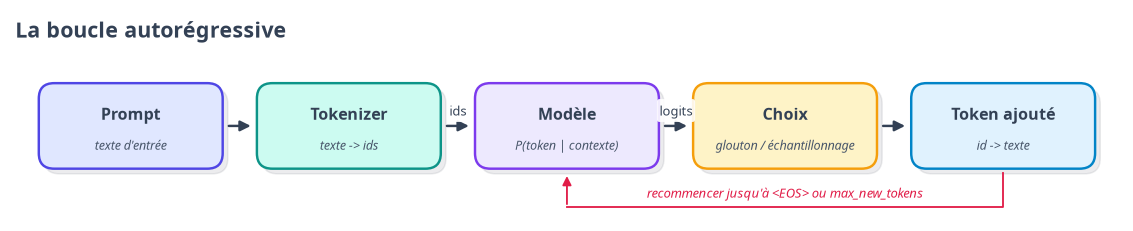

In [19]:
d = Diagram(13, 1.9, title="La boucle autorégressive")
d.flow([("p", "Prompt", "texte d'entrée"), ("t", "Tokenizer", "texte -> ids"),
        ("m", "Modèle", "P(token | contexte)"), ("s", "Choix", "glouton / échantillonnage"),
        ("o", "Token ajouté", "id -> texte")], y=1.1, x0=1.4, dx=2.55, w=2.15, h=1.0,
       labels=["", "ids", "logits", ""])  # y = 1.1 : boîtes entre 0,6 et 1,6
d.line([(11.6, 0.55), (11.6, 0.15), (6.5, 0.15), (6.5, 0.55)], color=ROSE, style="solid")
d.note(9.05, 0.32, "recommencer jusqu'à <EOS> ou max_new_tokens", color=ROSE, fontsize=8.5)
d.show()

> **À retenir.** Un LLM est une machine à compléter : tokenizer, distribution sur le
> prochain token, choix, et on boucle. Traduction, classification, code... tout peut être
> formulé comme une complétion, mais suivre une conversation demande un post-entraînement.

## Synthèse

- Un **modèle de langage** encode des statistiques d'une langue sous la forme
  $P(x_t \mid x_{<t})$ ; plus de contexte signifie moins d'incertitude (entropie de Shannon).
- Le **token** (souvent un sous-mot) est l'unité de calcul et de facturation. Le BPE
  construit le vocabulaire en fusionnant les paires fréquentes ; il réalise un compromis
  entre taille de vocabulaire et longueur de séquence, et ne connaît pas de mot inconnu.
- Le nombre de tokens dépend **du tokenizer et de la langue** : jusqu'à ×6 entre l'anglais
  et certaines langues avec un vieux tokenizer.
- **Masqué** (remplir un trou, contexte bidirectionnel) contre **autorégressif** (prédire
  la suite, contexte passé) : la différence tient au masque d'attention.
- Un modèle autorégressif est une **machine à compléter** : beaucoup de tâches s'y
  ramènent, mais converser demande un post-entraînement.

**Liens.** Le notebook suivant (cours 2) explique comment ces modèles apprennent sans
étiquettes (**auto-supervision**) et pourquoi cela a permis l'explosion de leur taille.
Le chapitre 2 détaille l'architecture transformer, l'échantillonnage et le
post-entraînement ; le chapitre 5 exploite la vision « tout est complétion » pour
l'ingénierie de prompt.

In [20]:
llm.free_gpu()